# Report figure: the epistemic / aleatoric ratio

This notebook produces **one figure**, `fig_epistemic_aleatoric_ratio.pdf` (the five heads), for the subsection *The epistemic component is too small to move the calibration scores*, plus the numbers to quote in the text. Nothing else. The exploratory views (2-D cloud per donor, per-slide distributions, robustness of the filter) are not reported.

## What the figure has to establish

Every calibration score in this section is computed on the aleatoric term alone, that is, on the predictive of a single model. The question is what they would become under the full predictive uncertainty. The answer is a **magnitude**, not a recomputation: the total variance is `sigma2_ale + sigma2_epi`, so the predictive standard deviation is multiplied by

```
sigma_total / sigma_aleatoric = sqrt(1 + r)      with r = sigma2_epi / sigma2_ale
```

It is therefore enough to bound `r`. At `r = 1e-2` the predictive interval widens by 0.5%, at `r = 1e-4` by 0.005%. An inflation of that size cannot move a calibration error that ranges from 0.042 to 0.217 depending on the head.

## The figure

One row per head, one column per cohort, the **three epistemic estimators** superposed (MC-dropout and Laplace on the `pr_classic1` weights, Deep Ensemble on `de_6`), aggregated over the slides of the cohort. A single reference: the `r = 1` vertical, where the two components would balance.

Three plotting choices, all checkable below:

- **Aggregating over slides is an exact sum.** The log10 ratio grid is fixed and identical in every artifact, so the slides' histograms share their edges. The sum weights by the number of entries: it is the cohort's distribution, not the average of its slides.
- **The two edge bins are dropped from the curve.** The precompute folds whatever falls outside the grid into them, which is right for accounting but draws a false peak at the edge of the axis. The dropped share is printed (`frac_off_grid`).
- **One axis only.** The `sqrt(1+r)` reading stays in the caption and the text. A second axis carrying the same quantity would force the reader to translate between the two for nothing.

No median is drawn: the only vertical in a panel is `r = 1`. The aggregated medians are **printed numbers** (table `REPORT`), where they serve the text without cluttering a figure in which three curves already overlap.

## Two things the ratio does and does not say

- **The ratio is dimensionless**, hence comparable across heads and across cohorts, unlike the variances themselves, which live on each head's own axis (`log1p(CP10k)` for the Gaussians, CP10k for the count heads).


## 0. Config and loading

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)

RESULTS  = PROJ / 'results'
DATASETS = ['10x_TuPro', 'TLS', 'LUNG_CANCER']
RADIUS   = 'r75'
FILT     = 'ypos'   # observed y>0: the population every calibration number in the section uses

# MC-dropout and Laplace are two post-hoc estimators on the SAME pr_classic1 checkpoints;
# the deep ensemble is de_6, a re-trained arm (see the header warning).
POSTHOC  = dict(label='pr_classic1', run_id='pr_classic1')
ENSEMBLE = dict(label='de_6',        run_id='de_6')

METHODS = ['mc_dropout', 'laplace', 'deep_ensemble']
METHOD_LABELS = {'mc_dropout': 'MC-dropout', 'laplace': 'Laplace',
                 'deep_ensemble': 'Deep Ensemble'}
# COLOR ENCODES THE ESTIMATOR, not the model: one panel is ONE head, so the model is constant
# within a panel and the only free axis is the estimator. matplotlib's BASE_COLORS b / g / r,
# fully saturated, so the three read at equal visual weight.
# KNOWN COLLISION, accepted deliberately: these are the saturated twins of the tab10 blue /
# green / red that denote gene-homoscedastic, spot-homoscedastic and Poisson elsewhere in the
# report. It holds here because the legend names the estimators and no panel of THIS figure ever
# encodes a model by color. Do not carry this palette into a figure where models are.
METHOD_COLORS = {'mc_dropout': 'b', 'laplace': 'g', 'deep_ensemble': 'r'}
# Solid outline + light shading underneath. All three lines are solid, so the fill is what keeps
# them separable where they overlap, and no estimator is relegated to a faint dotted line.
FILL_ALPHA = 0.1

# The 5 heads all three estimators cover on the shared reporting axis.
HEADS = ['homoscedastic', 'heteroscedastic', 'spot_homoscedastic',
         'poisson_cp', 'negativebinomial_hetero_noanchor_cp']
GAUSSIAN_HEADS = {'homoscedastic', 'heteroscedastic', 'spot_homoscedastic'}
HEAD_LABELS = {
    'homoscedastic':                        'Gaussian\ngene-homoscedastic',
    'heteroscedastic':                      'Gaussian\nheteroscedastic',
    'spot_homoscedastic':                   'Gaussian\nspot-homoscedastic',
    'poisson_cp':                           'Poisson',
    'negativebinomial_hetero_noanchor_cp':  'Negative binomial',
}
DATASET_LABELS = {'10x_TuPro': 'Tumor Profiler', 'TLS': 'Kidney/Lung with TLS',
                  'LUNG_CANCER': 'NSCLC'}

FIGDIR = PROJ / 'results' / '_analysis' / 'figures'
FIGDIR.mkdir(parents=True, exist_ok=True)
FIGNAME = 'fig_epistemic_aleatoric_ratio'

def artifact_dir(dataset, head, method):
    """Where epi_ale_density_precompute.py wrote this (dataset, head, method). The ensemble leaf
    has NO lambda_ level (ensemble.lambda is constant across members and dropped from the path);
    the single-model Gaussian leaf does."""
    if method == 'deep_ensemble':
        base = (RESULTS / dataset / ENSEMBLE['run_id']
                / f'_{dataset}_hvg_top3000' / RADIUS / head)
        return base / 'ensemble' / 'epi_ale_density'
    leaf = f'{head}/lambda_0.0' if head in GAUSSIAN_HEADS else head
    base = (RESULTS / dataset / POSTHOC['run_id']
            / f'_{dataset}_hvg_top3000' / RADIUS / leaf)
    return base / method / 'epi_ale_density'

# ── Load: only ratio.parquet + summary.json (the 2-D density is another notebook's business) ──
RATIO, SUMM, MISSING = {}, {}, []
for ds in DATASETS:
    for head in HEADS:
        for m in METHODS:
            d = artifact_dir(ds, head, m)
            if not (d / 'ratio.parquet').is_file():
                MISSING.append((ds, head, m, str(d)))
                continue
            SUMM[(ds, head, m)]  = json.loads((d / 'summary.json').read_text())
            RATIO[(ds, head, m)] = pd.read_parquet(d / 'ratio.parquet')

print(f'loaded {len(SUMM)} / {len(DATASETS) * len(HEADS) * len(METHODS)} artifacts')
for ds, head, m, path in MISSING:
    print(f'  MISSING  {ds:<12} {head:<38} {m:<14} {path}')
if not SUMM:
    raise SystemExit('nothing loaded -- run snake/scripts/canals/launch_epi_ale_density_precompute.sh first')

# The ratio grid is FIXED by design, and the whole figure rests on that: it is what makes the
# per-slide histograms summable and the panels comparable. Assert it rather than trust it.
rgrids = {(s['grid']['ratio_lo'], s['grid']['ratio_hi'], s['grid']['ratio_step'])
          for s in SUMM.values()}
assert len(rgrids) == 1, f'artifacts disagree on the FIXED ratio grid: {rgrids}'
print('ratio grid (fixed, log10, shared by every artifact): lo, hi, step =', next(iter(rgrids)))

# Per-slide stats, for the tail number and the off-grid accounting.
RSTATS = pd.DataFrame([dict(dataset=k[0], head=k[1], method=k[2], **r)
                       for k, s in SUMM.items() for r in s['per_slide']])
RSTATS = RSTATS[RSTATS['filt'] == FILT]
print(f'per-(head, slide, method) rows at filter {FILT}:', len(RSTATS))

loaded 45 / 45 artifacts
ratio grid (fixed, log10, shared by every artifact): lo, hi, step = (-10.0, 3.0, 0.02)
per-(head, slide, method) rows at filter ypos: 900


## 1. The figure and the numbers

The cell writes `fig_epistemic_aleatoric_ratio.pdf` and `.png` into `results/_analysis/figures/`, **6.3 inches wide**, exactly the paper's `\textwidth`, so that `width=\textwidth` does not rescale the fonts.

It then prints the numbers to quote. Two of them matter:

- the **aggregated median** of `r` (the typical case) and its inflation `sqrt(1+r) - 1`;
- the **worst per-slide q90** of the whole study (the tail), so the claim holds somewhere other than at the median.

Alongside those: the spread between the three estimators on one head, and `frac_off_grid`, the share of entries the log grid could not place and that the curve therefore leaves out.

x range: 8.18e-07 to 405
saved -> fig_epistemic_aleatoric_ratio.pdf


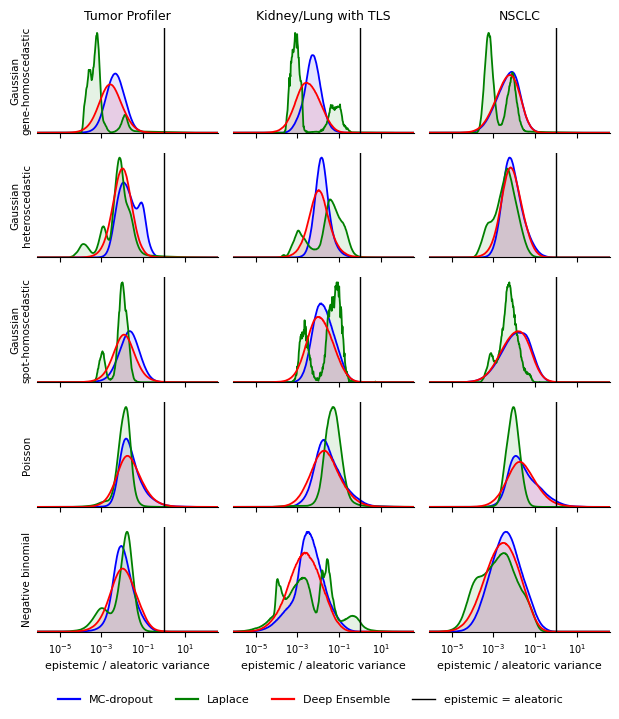


REPORT NUMBERS (filter ypos).  r = epistemic/aleatoric variance.  sd inflation = sqrt(1+r) - 1.
frac_off_grid = entries the log grid could not place (zero ratio, or outside the fixed range); these are the bins the curve drops.
                               head     dataset        method  r_pooled_median  sd_infl_median_pct  r_worst_slide_q90  sd_infl_worst_pct  frac_gt_1  frac_off_grid
                      homoscedastic   10x_TuPro    mc_dropout         0.004677              0.2336            0.03264              1.619  6.581e-07              0
                      homoscedastic   10x_TuPro       laplace         0.000537             0.02685            0.02827              1.404    0.02299      2.781e-06
                      homoscedastic   10x_TuPro deep_ensemble         0.002692              0.1345            0.04784              2.364  5.621e-06              0
                      homoscedastic         TLS    mc_dropout          0.00537              0.2682             0.0285   

In [2]:
def ratio_curve_pooled(key):
    """The ratio histogram of ONE artifact, POOLED over that cohort's slides.

    The pooling is an exact SUM, not a re-estimate: the log10 grid is fixed and identical in
    every artifact, so the slides' histograms share their bin edges. It is entry-weighted, so a
    bigger slide contributes more, which is what 'the cohort's distribution' means.

    THE TWO EDGE BINS ARE DROPPED. The precompute folds everything outside the fixed grid into
    bin 0 and bin n-1, which is right for accounting (it is counted in n_below / n_above) but
    wrong for a density curve: the folded mass piles into one bin and draws a spike at the axis
    edge that reads as a real mode. frac_off_grid below reports how much that is.

    Returns (x in ratio units for a LOG axis, density per dex, pooled median). The median is a
    REPORTED NUMBER ONLY -- it is not drawn on the figure, which keeps a single reference
    line (r = 1) as the header promises."""
    g = SUMM[key]['grid']
    n, lo, step = g['ratio_n_bins'], g['ratio_lo'], g['ratio_step']
    d = RATIO[key]
    d = d[d['filt'] == FILT]
    if d.empty:
        return None, None, np.nan
    agg = d.groupby('ib')['count'].sum()
    h = np.zeros(n, dtype=float)
    h[agg.index.to_numpy()] = agg.to_numpy().astype(float)
    h[0] = h[-1] = 0.0
    if h.sum() <= 0:
        return None, None, np.nan
    xs = 10.0 ** (lo + (np.arange(n) + 0.5) * step)
    dens = h / (h.sum() * step)
    med = float(xs[min(int(np.searchsorted(np.cumsum(dens * step), 0.5)), n - 1)])
    return xs, dens, med

CURVES = {k: ratio_curve_pooled(k) for k in SUMM}

# One x range for the WHOLE figure: the central 99.8% of every pooled curve with a
# multiplicative margin, and a right edge forced past 1 so the r = 1 reference appears in every
# panel rather than only in the panels that happen to reach it.
los, his = [], []
for key, (xs, dens, _) in CURVES.items():
    if xs is None:
        continue
    c = np.cumsum(dens * SUMM[key]['grid']['ratio_step'])
    los.append(xs[min(int(np.searchsorted(c, 0.001)), xs.size - 1)])
    his.append(xs[min(int(np.searchsorted(c, 0.999)), xs.size - 1)])
XLIM = (min(los) / 3.0, max(max(his) * 3.0, 2.0))
print(f'x range: {XLIM[0]:.3g} to {XLIM[1]:.3g}')

def draw_ratio_figure(heads, figname, figsize):
    """The figure, restricted to the heads passed in: one row per head, one column per cohort,
    the three estimators superposed, and r = 1 as the ONLY reference line.

    Called twice -- once for the five heads, once for the heteroscedastic Gaussian row alone --
    with the same XLIM in both, so the single-row version is literally that row of the full
    figure and the two can be read side by side without re-scaling the eye."""
    fig, axes = plt.subplots(len(heads), len(DATASETS), figsize=figsize,
                             sharex=True, squeeze=False)
    for r, head in enumerate(heads):
        for c, ds in enumerate(DATASETS):
            ax = axes[r][c]
            for m in METHODS:
                key = (ds, head, m)
                if key not in CURVES:
                    continue
                xs, dens, _ = CURVES[key]
                if xs is None:
                    continue
                # Solid outline + light shading. The three curves overlap heavily, so the fill is
                # what separates them; the outline is what stays readable where they cross.
                ax.fill_between(xs, dens, color=METHOD_COLORS[m], alpha=FILL_ALPHA, lw=0, zorder=1)
                ax.plot(xs, dens, color=METHOD_COLORS[m], lw=1.3, zorder=2)
            ax.axvline(1.0, color='k', lw=1.0, zorder=3)   # epistemic == aleatoric
            ax.set_xscale('log')
            ax.set_xlim(*XLIM)
            ax.set_ylim(bottom=0)                          # a density starts at 0; the fill needs it
            ax.set_yticks([])
            ax.tick_params(axis='x', labelsize=7)
            for side in ('top', 'right', 'left'):
                ax.spines[side].set_visible(False)
            if c == 0:
                ax.set_ylabel(HEAD_LABELS.get(head, head), fontsize=7.5)
            if r == 0:
                ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=9)
            if r == len(heads) - 1:
                ax.set_xlabel('epistemic / aleatoric variance', fontsize=8)
    handles = [plt.Line2D([], [], color=METHOD_COLORS[m], lw=1.6, label=METHOD_LABELS[m])
               for m in METHODS]
    handles.append(plt.Line2D([], [], color='k', lw=1.0, label='epistemic = aleatoric'))
    fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, fontsize=8,
               bbox_to_anchor=(0.5, 0.0))
    fig.tight_layout(rect=[0, 0.04, 1, 1])
    for suffix in ('pdf', 'png'):
        fig.savefig(FIGDIR / f'{figname}.{suffix}', dpi=300, bbox_inches='tight')
    print('saved ->', f'{figname}.pdf')
    return fig

fig = draw_ratio_figure(HEADS, FIGNAME, (6.3, 7.2))
plt.show()

# ── The numbers to quote ─────────────────────────────────────────────────────────────────────
# sd_infl = sqrt(1 + r) - 1, the relative increase of the predictive standard deviation once the
# epistemic term is added: the only channel by which it could move a calibration score.
rep = []
for head in HEADS:
    for ds in DATASETS:
        for m in METHODS:
            key = (ds, head, m)
            if key not in CURVES:
                continue
            med = CURVES[key][2]
            sl = RSTATS[(RSTATS['head'] == head) & (RSTATS['dataset'] == ds)
                        & (RSTATS['method'] == m)]
            q90 = float(sl['ratio_q90'].max())
            rep.append(dict(
                head=head, dataset=ds, method=m,
                r_pooled_median=med, sd_infl_median_pct=100 * (np.sqrt(1 + med) - 1),
                r_worst_slide_q90=q90, sd_infl_worst_pct=100 * (np.sqrt(1 + q90) - 1),
                frac_gt_1=float(sl['frac_gt_1'].max()),
                frac_off_grid=float((sl['n_below'].sum() + sl['n_above'].sum()
                                     + sl['n_zero'].sum()) / sl['n_used'].sum())))
REPORT = pd.DataFrame(rep)
print()
print('=' * 122)
print(f'REPORT NUMBERS (filter {FILT}).  r = epistemic/aleatoric variance.  '
      'sd inflation = sqrt(1+r) - 1.')
print('frac_off_grid = entries the log grid could not place (zero ratio, or outside the fixed '
      'range); these are the bins the curve drops.')
print('=' * 122)
print(REPORT.to_string(index=False, float_format=lambda v: f'{v:.4g}'))

sp = REPORT.groupby(['head', 'dataset'])['r_pooled_median'].agg(['min', 'max'])
print()
print('HEADLINE -- the sentences of the results text are written from these:')
print(f'  largest pooled median r, over 5 heads x 3 cohorts x 3 estimators : '
      f'{REPORT["r_pooled_median"].max():.3g}'
      f'   -> sd inflation {REPORT["sd_infl_median_pct"].max():.3g}%')
print(f'  largest per-slide q90 of r anywhere                              : '
      f'{REPORT["r_worst_slide_q90"].max():.3g}'
      f'   -> sd inflation {REPORT["sd_infl_worst_pct"].max():.3g}%')
print(f'  largest fraction of (spot,gene) entries with r > 1, any slide    : '
      f'{REPORT["frac_gt_1"].max():.3g}')
print(f'  largest spread between the three estimators (max/min of the pooled median,\n'
      f'    within one head x cohort)                                      : '
      f'{(sp["max"] / sp["min"]).max():.3g}x')
print(f'  largest share of entries dropped from any curve                  : '
      f'{REPORT["frac_off_grid"].max():.3g}')